# Relación entre el nivel educativo y la recogida selectiva de residuos en España

**Proyecto académico · Grado en Ciencia de Datos · Universitat Politècnica de València (UPV)**

## 1. Introducción

Este análisis explora la posible relación entre el nivel educativo de la población y la cantidad de residuos recogidos por persona en las comunidades autónomas españolas durante 2023. Se estudian por separado los indicadores de educación alta y educación baja.

El análisis es **exploratorio y correlacional**: permite identificar asociaciones entre variables, pero no demostrar que el nivel educativo cause un mayor o menor reciclaje.

## 2. Objetivos

- Integrar información educativa y de recogida de residuos por comunidad autónoma.
- Examinar la relación entre el porcentaje de población con educación alta y los residuos recogidos por persona.
- Repetir el análisis para el porcentaje de población con educación baja.
- Representar las relaciones mediante gráficos y calcular la correlación de Pearson.

## 3. Herramientas

- **Python**
- **Pandas** para la lectura, limpieza e integración de datos.
- **Matplotlib** y **Seaborn** para la visualización.

## 4. Archivos necesarios

Para ejecutar este notebook se deben tener los siguientes archivos en la carpeta `data/` del repositorio:

- `nivelEducacionAltoBO(in).csv`
- `nivelEducacionBajoBO(in).csv`
- `residuos_2023.csv`

Si no es así, ajusta las rutas de la siguiente celda.

## 5. Importación de librerías y configuración

Importamos las bibliotecas necesarias y definimos las rutas relativas a los archivos. No se instalan paquetes automáticamente: si falta alguno, instálalo en tu entorno de Python.

In [3]:
from pathlib import Path
import unicodedata

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


DATA_DIR = Path('.')

ARCHIVO_EDUCACION_ALTA = DATA_DIR / 'nivelEducacionAltoBO(in).csv'
ARCHIVO_EDUCACION_BAJA = DATA_DIR / 'nivelEducacionBajoBO(in).csv'
ARCHIVO_RESIDUOS = DATA_DIR / 'residuos_2023.csv'

archivos = [ARCHIVO_EDUCACION_ALTA, ARCHIVO_EDUCACION_BAJA, ARCHIVO_RESIDUOS]
for archivo in archivos:
    if not archivo.exists():
        raise FileNotFoundError(
            f'No se encuentra {archivo}. Comprueba que el archivo está en la carpeta data/ '
            'y que ejecutas el notebook desde la carpeta notebooks/.'
        )

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', None)

## 6. Funciones auxiliares

Para poder unir las tablas, normalizamos los nombres de las comunidades autónomas: eliminamos espacios sobrantes, convertimos el texto a minúsculas y retiramos las tildes.

También definimos una función para leer los ficheros educativos y asignar nombres claros a sus dos columnas.

In [5]:
def normalizar_comunidad(texto):
    """Normaliza un nombre de comunidad para facilitar la unión entre tablas."""
    texto = str(texto).strip().lower()

    # Eliminar tildes y normalizar caracteres
    texto = unicodedata.normalize('NFKD', texto)
    texto = ''.join(
        caracter for caracter in texto
        if not unicodedata.combining(caracter)
    )

    # Unificar nombres de comunidades
    if 'andaluci' in texto:
        return 'andalucia'

    if 'cataluny' in texto or 'cataluna' in texto:
        return 'cataluna'

    return texto


def cargar_educacion(ruta, nombre_columna):
    """Lee un CSV educativo y devuelve columnas con nombres homogéneos.

    Se omite la primera fila, siguiendo el formato utilizado en el análisis original.
    """
    datos = pd.read_csv(ruta, sep=';', skiprows=1)
    if datos.shape[1] < 2:
        raise ValueError(f'El archivo {ruta.name} no contiene las dos columnas esperadas.')
    datos = datos.iloc[:, :2].copy()
    datos.columns = ['Comunidad', nombre_columna]
    datos['Comunidad_normalizada'] = datos['Comunidad'].map(normalizar_comunidad)
    datos[nombre_columna] = pd.to_numeric(datos[nombre_columna], errors='coerce')
    return datos


def cargar_residuos(ruta):
    """Lee los datos de residuos y comprueba que existen las columnas esperadas."""
    datos = pd.read_csv(ruta, sep=',')
    columnas_esperadas = ['Comunidad Autonoma', 'Residuos (kg) por persona']
    faltantes = [col for col in columnas_esperadas if col not in datos.columns]
    if faltantes:
        raise ValueError(
            f'Faltan columnas en {ruta.name}: {faltantes}. '
            f'Columnas encontradas: {list(datos.columns)}'
        )
    datos = datos.copy()
    datos['Comunidad_normalizada'] = datos['Comunidad Autonoma'].map(normalizar_comunidad)
    datos['Residuos (kg) por persona'] = pd.to_numeric(
        datos['Residuos (kg) por persona'], errors='coerce'
    )
    return datos

## 7. Carga y exploración inicial de los datos

Leemos las tres fuentes y comprobamos sus dimensiones y primeras filas antes de integrarlas.

In [7]:
educacion_alta = cargar_educacion(ARCHIVO_EDUCACION_ALTA, 'Porcentaje_educacion_alta')
educacion_baja = cargar_educacion(ARCHIVO_EDUCACION_BAJA, 'Porcentaje_educacion_baja')
residuos = cargar_residuos(ARCHIVO_RESIDUOS)

print('Educación alta:', educacion_alta.shape)
print('Educación baja:', educacion_baja.shape)
print('Residuos:', residuos.shape)

display(educacion_alta.head())
display(educacion_baja.head())
display(residuos.head())

Educación alta: (19, 3)
Educación baja: (19, 3)
Residuos: (19, 10)


,Comunidad,Porcentaje_educacion_alta,Comunidad_normalizada
0,Andalucía,32.7,andalucia
1,Aragón,39.2,aragon
2,Asturias,40.2,asturias
3,Illes Balears,30.4,illes balears
4,Canarias,31.6,canarias


,Comunidad,Porcentaje_educacion_baja,Comunidad_normalizada
0,Andalucía,42.9,andalucia
1,Aragón,34.6,aragon
2,Asturias,31.7,asturias
3,Illes Balears,39.3,illes balears
4,Canarias,38.6,canarias


,Año,Comunidad Autonoma,Nº de contenedores,Envases de vidrio (kg) recogidos,Poblacion Total,Vidrio (kg) por persona,Envases (kg) por persona,Papel (kg) por persona,Residuos (kg) por persona,Comunidad_normalizada
0,2023,Andaluci­a,40485,133956456,8663175,15.462744,12.949234,11.442232,39.854210,andalucia
1,2023,Aragon,7270,19994179,1352630,14.781706,18.464093,17.907529,51.153328,aragon
2,2023,Asturias,5121,17535845,1014112,17.291823,10.869014,14.781690,42.942527,asturias
3,2023,Illes Balears,5485,52245267,1244394,41.984506,38.833333,33.079167,113.897006,illes balears
4,2023,Canarias,12760,52027340,2258219,23.039103,14.331111,15.682222,53.052436,canarias


## 8. Integración de los conjuntos de datos

Unimos cada indicador educativo con la tabla de residuos utilizando el nombre normalizado de la comunidad autónoma. Se utiliza una unión interna (`inner`), por lo que solo permanecen las comunidades que aparecen en ambas fuentes.

Después comprobamos cuántas comunidades se han podido emparejar y si existen valores ausentes en las variables del análisis.

In [9]:
datos_alta = residuos.merge(
    educacion_alta[['Comunidad_normalizada', 'Porcentaje_educacion_alta']],
    on='Comunidad_normalizada',
    how='inner',
    validate='one_to_one'
)

datos_baja = residuos.merge(
    educacion_baja[['Comunidad_normalizada', 'Porcentaje_educacion_baja']],
    on='Comunidad_normalizada',
    how='inner',
    validate='one_to_one'
)

print(f'Comunidades emparejadas (educación alta): {len(datos_alta)}')
print(f'Comunidades emparejadas (educación baja): {len(datos_baja)}')

display(datos_alta[['Comunidad Autonoma', 'Porcentaje_educacion_alta', 'Residuos (kg) por persona']])
display(datos_baja[['Comunidad Autonoma', 'Porcentaje_educacion_baja', 'Residuos (kg) por persona']])

print('Valores ausentes en educación alta y residuos:')
display(datos_alta[['Porcentaje_educacion_alta', 'Residuos (kg) por persona']].isna().sum())
print('Valores ausentes en educación baja y residuos:')
display(datos_baja[['Porcentaje_educacion_baja', 'Residuos (kg) por persona']].isna().sum())

Comunidades emparejadas (educación alta): 19
Comunidades emparejadas (educación baja): 19


,Comunidad Autonoma,Porcentaje_educacion_alta,Residuos (kg) por persona
0,Andaluci­a,32.7,39.854210
1,Aragon,39.2,51.153328
2,Asturias,40.2,42.942527
3,Illes Balears,30.4,113.897006
4,Canarias,31.6,53.052436
5,Cantabria,45.4,56.044405
6,Castilla - La Mancha,30.4,44.624668
7,Castilla y Leon,37.7,51.372915
8,Cataluña,40.4,77.732252
9,Ceuta,18.8,16.523199


,Comunidad Autonoma,Porcentaje_educacion_baja,Residuos (kg) por persona
0,Andaluci­a,42.9,39.854210
1,Aragon,34.6,51.153328
2,Asturias,31.7,42.942527
3,Illes Balears,39.3,113.897006
4,Canarias,38.6,53.052436
5,Cantabria,27.6,56.044405
6,Castilla - La Mancha,45.0,44.624668
7,Castilla y Leon,35.3,51.372915
8,Cataluña,34.2,77.732252
9,Ceuta,60.1,16.523199


Valores ausentes en educación alta y residuos:


Porcentaje_educacion_alta    0
Residuos (kg) por persona    0
dtype: int64

Valores ausentes en educación baja y residuos:


Porcentaje_educacion_baja    0
Residuos (kg) por persona    0
dtype: int64

## 9. Análisis de educación alta

Representamos el porcentaje de población con educación alta frente a los kilogramos de residuos recogidos por persona. La recta de regresión sirve para visualizar la tendencia lineal.

Calculamos la correlación de Pearson, que mide la intensidad y dirección de la asociación lineal entre ambas variables. Su valor está comprendido entre -1 y 1.

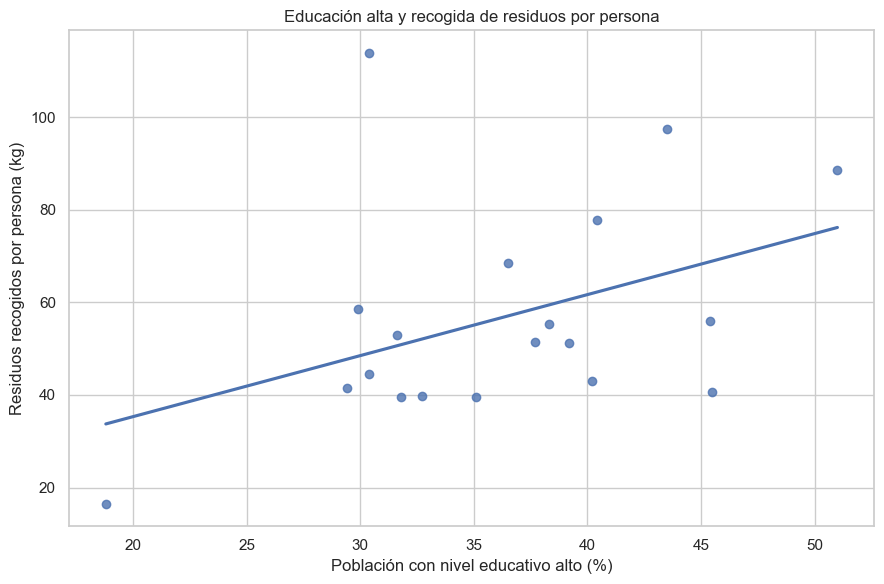

Correlación de Pearson (educación alta): 0.419


In [11]:
analisis_alta = datos_alta.dropna(
    subset=['Porcentaje_educacion_alta', 'Residuos (kg) por persona']
)

plt.figure(figsize=(9, 6))
sns.regplot(
    data=analisis_alta,
    x='Porcentaje_educacion_alta',
    y='Residuos (kg) por persona',
    ci=None,
    scatter_kws={'alpha': 0.8}
)
plt.title('Educación alta y recogida de residuos por persona')
plt.xlabel('Población con nivel educativo alto (%)')
plt.ylabel('Residuos recogidos por persona (kg)')
plt.tight_layout()
plt.show()

correlacion_alta = analisis_alta['Porcentaje_educacion_alta'].corr(
    analisis_alta['Residuos (kg) por persona'], method='pearson'
)
print(f'Correlación de Pearson (educación alta): {correlacion_alta:.3f}')

## 10. Análisis de educación baja

Repetimos el procedimiento utilizando el porcentaje de población con nivel educativo bajo.

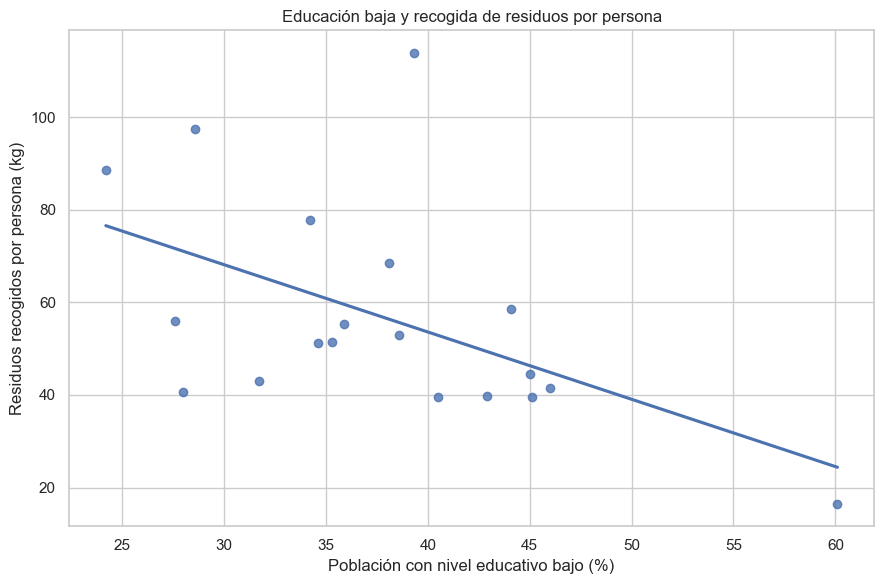

Correlación de Pearson (educación baja): -0.524


In [13]:
analisis_baja = datos_baja.dropna(
    subset=['Porcentaje_educacion_baja', 'Residuos (kg) por persona']
)

plt.figure(figsize=(9, 6))
sns.regplot(
    data=analisis_baja,
    x='Porcentaje_educacion_baja',
    y='Residuos (kg) por persona',
    ci=None,
    scatter_kws={'alpha': 0.8}
)
plt.title('Educación baja y recogida de residuos por persona')
plt.xlabel('Población con nivel educativo bajo (%)')
plt.ylabel('Residuos recogidos por persona (kg)')
plt.tight_layout()
plt.show()

correlacion_baja = analisis_baja['Porcentaje_educacion_baja'].corr(
    analisis_baja['Residuos (kg) por persona'], method='pearson'
)
print(f'Correlación de Pearson (educación baja): {correlacion_baja:.3f}')

## 11. Comparación de resultados

La siguiente tabla reúne los coeficientes de correlación calculados en ambos análisis. Los valores se generan al ejecutar el notebook con los archivos de datos correspondientes.

In [15]:
resumen_correlaciones = pd.DataFrame({
    'Indicador educativo': ['Educación alta', 'Educación baja'],
    'Coeficiente de correlación de Pearson': [correlacion_alta, correlacion_baja],
    'Número de comunidades analizadas': [len(analisis_alta), len(analisis_baja)]
})
display(resumen_correlaciones)

,Indicador educativo,Coeficiente de correlación de Pearson,Número de comunidades analizadas
0,Educación alta,0.419289,19
1,Educación baja,-0.523503,19


## 12. Interpretación y limitaciones

Al interpretar los coeficientes, conviene considerar tanto su signo como su magnitud:

- Un coeficiente positivo indica que valores mayores de una variable tienden a asociarse con valores mayores de la otra.
- Un coeficiente negativo indica que valores mayores de una variable tienden a asociarse con valores menores de la otra.
- Un valor próximo a cero indica una asociación lineal débil.

**Limitaciones del análisis:**

- La unidad de análisis es la comunidad autónoma, no cada persona individual. Por tanto, los resultados agregados no permiten concluir cómo se comporta cada individuo (riesgo de falacia ecológica).
- La correlación no implica causalidad. Otros factores sociales, económicos, territoriales o relacionados con los sistemas de recogida pueden influir en los residuos recogidos.
- El análisis se limita a los datos disponibles para el periodo y las variables seleccionadas.
- Antes de extraer conclusiones definitivas, es importante verificar que las definiciones, unidades y periodos de referencia de las fuentes sean comparables.

## 13. Conclusiones

Completa este apartado después de ejecutar el notebook y revisar los coeficientes y gráficos. Describe la dirección y la intensidad de cada asociación, compara ambos resultados y evita atribuir causalidad. No se incluyen aquí conclusiones numéricas prefijadas para no anticipar resultados sin ejecutar el análisis con los archivos definitivos.

## 14. Autoría y contexto académico

Análisis realizado como parte de un proyecto universitario del Grado en Ciencia de Datos de la Universitat Politècnica de València (UPV).

> Para reproducir el análisis, descarga el repositorio completo, conserva la estructura de carpetas indicada y ejecuta las celdas en orden desde este notebook.